# Causal forests: who gains from a 401(k) plan?

An average effect hides who drives it. A causal forest estimates the effect for every combination of
covariates,

$$
\tau(x) = E[Y(1) - Y(0) \mid X = x],
$$

with a confidence interval at each point (Athey, Tibshirani and Wager, 2019; R's `grf`). This notebook
uses the 401(k) data of Chernozhukov and Hansen (2004): net financial assets of 9,915 US households,
eligibility for an employer's 401(k) plan, and nine covariates. Eligibility is not randomised, but
conditional on income, age and the other covariates it is plausibly as good as random.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dml_rs

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Bad certificate")  # Windows certificate store, while downloading
pd.set_option("display.precision", 3)

df = dml_rs.datasets.fetch_401K(return_type="DataFrame")
covariates = ["age", "inc", "educ", "fsize", "marr", "twoearn", "db", "pira", "hown"]
X, y, d = df[covariates], df["net_tfa"], df["e401"]
df[["net_tfa", "e401", "p401", "inc", "age"]].describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
net_tfa,18051.533,63522.500,-502302.0,1.537e+06
e401,0.371,0.483,0.0,1.000e+00
p401,0.262,0.440,0.0,1.000e+00
inc,37200.621,24774.289,-2652.0,2.421e+05
age,41.060,10.345,25.0,6.400e+01


## A first forest

`CausalForest` takes a learner for the outcome, $E[Y \mid X]$, and one for the treatment,
$E[D \mid X]$ (a classifier, since eligibility is binary). Both are cross-fitted, and the forest is
grown on the residuals. Histogram gradient boosting is a good default for both.

In [2]:
cf = dml_rs.CausalForest(
    dml_rs.HistGradientBoostingRegressor(), dml_rs.HistGradientBoostingClassifier()
).fit(X, y, d)
cf.ate().summary

,coef,std err,t,P>|t|,2.5 %,97.5 %
e401,8581.07,1296.729,6.617,3.654e-11,6039.529,11122.611


The average effect from the forest's doubly robust scores is in line with the interactive regression
model estimates in the DoubleML literature. Before reading the individual effects, check whether the
forest's heterogeneity is real. `test_calibration` (grf's test) regresses the outcome residual on two
parts of the forest's prediction: its mean and its deviation from the mean. A coefficient near 1 on
`differential.forest.prediction` says the forest ranks households by effect size correctly.

In [3]:
cf.test_calibration()

,estimate,std. error,t value,Pr(>t)
mean.forest.prediction,1.142,0.158,7.244,2.183e-13
differential.forest.prediction,-0.264,0.388,-0.681,7.522e-01


The mean is right, but the differential coefficient is not significantly above zero. With the default
`min_node_size=5` the leaves are small, and net financial assets are extremely skewed (a standard
deviation of about 63,000 USD and a maximum of 1.5 million USD), so the individual estimates are
mostly noise. EconML's port of grf, grown on the same residuals, behaves the same way.

Larger leaves average over more households, trading some flexibility for much less noise:

In [4]:
cf = dml_rs.CausalForest(
    dml_rs.HistGradientBoostingRegressor(), dml_rs.HistGradientBoostingClassifier(), min_node_size=400
).fit(X, y, d)
cf.test_calibration()

,estimate,std. error,t value,Pr(>t)
mean.forest.prediction,1.015,0.133,7.653,9.770e-15
differential.forest.prediction,0.780,0.376,2.077,1.890e-02


The differential coefficient is now clearly positive and significant at the 5% level (one-sided).
This evidence is fragile, though: across other seeds and leaf sizes from 100 to 400 the coefficient
ranges from about 0.4 to 0.8, with p-values from 0.02 to 0.24. At the level of individual households,
the heterogeneity is real but only weakly identified. The group averages below are the sturdier
evidence. The average effect barely moves:

In [5]:
cf.ate().summary

,coef,std err,t,P>|t|,2.5 %,97.5 %
e401,8228.799,1293.127,6.363,1.972e-10,5694.317,10763.281


## Which covariates matter?

`variable_importance_` is grf's split-frequency measure: how often each covariate is used to split,
with shallow splits weighted more.

In [6]:
pd.Series(cf.variable_importance_, index=covariates).sort_values(ascending=False).round(3)

inc        0.679
age        0.209
educ       0.068
pira       0.017
twoearn    0.011
fsize      0.010
db         0.003
marr       0.002
hown       0.002
dtype: float64

## The effect along income

`effect` and `effect_interval` evaluate $\hat\tau(x)$ at any point. Here income varies and the other
covariates stay at their medians.

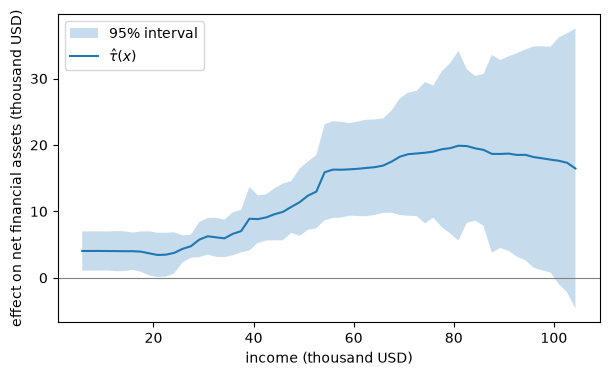

In [7]:
grid = pd.DataFrame(np.tile(X.median().to_numpy(), (60, 1)), columns=covariates)
grid["inc"] = np.linspace(X["inc"].quantile(0.02), X["inc"].quantile(0.98), 60)
tau = cf.effect(grid)
ci = cf.effect_interval(grid)

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(grid["inc"] / 1000, ci[:, 0] / 1000, ci[:, 1] / 1000, alpha=0.25, label="95% interval")
ax.plot(grid["inc"] / 1000, tau / 1000, label=r"$\hat\tau(x)$")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("income (thousand USD)")
ax.set_ylabel("effect on net financial assets (thousand USD)")
ax.legend()
plt.show()

Pointwise intervals are wide, so averages over groups are better for testing. `gate` gives group
average effects from the doubly robust scores, here for income quintiles:

In [8]:
quintile = pd.qcut(X["inc"], 5, labels=[f"income Q{k}" for k in range(1, 6)])
cf.gate(pd.get_dummies(quintile).astype(float)).summary

,coef,std err,t,P>|t|,[0.025,0.975]
income Q1,4407.802,1512.437,2.914,3.564e-03,1443.481,7372.123
income Q2,125.265,2022.772,0.062,9.506e-01,-3839.294,4089.824
income Q3,4727.706,1567.451,3.016,2.560e-03,1655.558,7799.854
income Q4,10193.023,2325.739,4.383,1.172e-05,5634.658,14751.387
income Q5,21690.200,5236.355,4.142,3.439e-05,11427.133,31953.268


Eligibility raises the savings of high-income households far more than those of low-income
households. The best linear predictor (`blp`) puts a slope on it:

In [9]:
basis = pd.DataFrame({"const": 1.0, "inc_10k": X["inc"] / 10_000})
cf.blp(basis).summary

,coef,std err,t,P>|t|,[0.025,0.975]
const,-2454.314,5061.366,-0.485,0.628,-12374.409,7465.781
inc_10k,2871.757,1565.220,1.835,0.067,-196.018,5939.531


## Participation, not eligibility: an instrumental forest

Eligibility is an intention to treat. The effect of *participating* in a plan (`p401`) is
confounded, since keen savers choose to participate, but eligibility is a valid instrument for it.
`InstrumentalForest` (R's `grf::instrumental_forest`) estimates the conditional local average
treatment effect

$$
\theta(x) = \frac{\operatorname{Cov}(Z, Y \mid X = x)}{\operatorname{Cov}(Z, D \mid X = x)},
$$

the effect of participation for households that participate because they are eligible (the
compliers). Only eligible households can participate, so the compliers are all eligible
participants.

In [10]:
iv = dml_rs.InstrumentalForest(
    dml_rs.HistGradientBoostingRegressor(),
    dml_rs.HistGradientBoostingClassifier(),
    dml_rs.HistGradientBoostingClassifier(),
    min_node_size=400,
).fit(X, y, df["p401"], d)
print(f"share of compliers: {iv.compliance_.mean():.2f}")
iv.ate().summary

share of compliers: 0.68


,coef,std err,t,P>|t|,2.5 %,97.5 %
p401,11504.016,1720.468,6.687,2.285e-11,8131.961,14876.071


The average conditional LATE agrees with the interactive IV model (`IIVM`), which estimates the
average directly:

In [11]:
dml_rs.IIVM(
    dml_rs.HistGradientBoostingRegressor(),
    dml_rs.HistGradientBoostingClassifier(),
    dml_rs.HistGradientBoostingClassifier(),
    subgroups={"always_takers": False, "never_takers": True},
).fit(X, y, df["p401"], d).summary

,coef,std err,t,P>|t|,2.5 %,97.5 %
p401,12216.238,1935.379,6.312,2.753e-10,8422.965,16009.512


The forest adds how the effect of participation varies:

In [12]:
iv.gate(pd.get_dummies(quintile).astype(float)).summary

,coef,std err,t,P>|t|,[0.025,0.975]
income Q1,6320.415,2613.363,2.418,1.558e-02,1198.318,11442.512
income Q2,825.287,2968.151,0.278,7.810e-01,-4992.181,6642.755
income Q3,7835.684,2229.727,3.514,4.411e-04,3465.499,12205.869
income Q4,14695.053,3109.658,4.726,2.294e-06,8600.234,20789.871
income Q5,27843.641,6595.559,4.222,2.426e-05,14916.583,40770.699


## Summary

- `CausalForest` estimates $\tau(x)$ with confidence intervals. `ate`, `gate` and `blp` turn the
  forest into tests on averages, and `test_calibration` checks whether its heterogeneity is real.
- With a heavy-tailed outcome, increase `min_node_size`: small leaves give noisy, uncalibrated
  individual effects. Group averages (`gate`, `blp`) are more robust than individual effects.
- `InstrumentalForest` does the same for an endogenous treatment with an instrument.
  `MultiArmCausalForest` handles several treatment levels, and `RegressionForest` and
  `QuantileForest` use the same engine as learners.